In [2]:
# Imports
import sys
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as mcolors
import warnings
warnings.filterwarnings('ignore')

from joblib import dump, load

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from scipy.stats import gaussian_kde
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture


In [ ]:
# Module versions

mods = {"pandas": pd, "numpy": np, "seaborn": sns,
        "matplotlib": getattr(plt, "matplotlib", None) or sys.modules.get("matplotlib"),
        "scikit-learn": sys.modules.get("sklearn"), "scipy": sys.modules.get("scipy"),
        "joblib": sys.modules.get("joblib")}
for n, m in mods.items(): print(f"{n:<14} {getattr(m, '__version__', 'not loaded') if m else 'not loaded'}")

pandas         2.3.2
numpy          1.24.4
seaborn        0.12.2
matplotlib     3.7.2
scikit-learn   1.7.2
scipy          1.11.1
joblib         1.2.0


In [4]:
#Plot functions for distributions
def plot_freq(data: pd.DataFrame | pd.Series, title: str, mode: str = "genes", bins: int = 32):
    """
    mode:
      - "series": plot the 1D series you pass in
      - "genes":  distribution of per-gene means  (mean across samples; uses columns)
      - "samples": distribution of per-sample means (mean across genes; uses rows)
      - "entries": distribution of all individual values
    """
    if mode == "series":
        arr = pd.Series(data).dropna()
    elif mode == "genes":
        # columns = genes, rows = samples
        arr = (data.mean(axis=0) if isinstance(data, pd.DataFrame) else pd.Series(data)).dropna()
    elif mode == "samples":
        arr = (data.mean(axis=1) if isinstance(data, pd.DataFrame) else pd.Series(data)).dropna()
    elif mode == "entries":
        arr = pd.Series(np.asarray(data).ravel()).dropna()
    else:
        raise ValueError("mode must be one of {'series','genes','samples','entries'}")

    sns.histplot(arr, kde=True, bins=bins, color="dodgerblue", edgecolor=None)
    plt.xlabel(title)
    plt.ylabel("frequency")
    plt.tight_layout()
    plt.show()


In [5]:
#Load Datasets
transcriptomics = load('data/transcriptomics_matched.joblib')
proteomics = load('data/proteomics_matched.joblib')

In [6]:
#No nans and shape check
print(transcriptomics.T.isna().sum().sum(), transcriptomics.isna().sum().sum())
print(proteomics.T.isna().sum().sum(), proteomics.isna().sum().sum())
print(transcriptomics.shape, proteomics.shape)


0 0
0 0
(369, 51989) (369, 5113)


## Explorative plots
transcriptomics explorative data analysis
- mean gene expression distribution
- std gene expression distribution
- mean expression dsitribution across samples
- frequency of non zero values for genes

In [ ]:
# Check of 0 values 
# percent of zero values
(transcriptomics == 0).sum().sum() / (transcriptomics.shape[0] * transcriptomics.shape[1])

0.47357167122229993

 The mean histogram has a giant spike near zero with a long right tail, indicating many genes are mostly off and a smaller set are clearly expressed; the KDE valley sits just to the right of that spike, marking the transition into the expressed regime. The std histogram shows an even clearer second bump at moderate std with a trough between the near-zero spike and that bump.

In [8]:
#Check of 0 values
(transcriptomics == 0).sum().sum() / (transcriptomics.shape[0] * transcriptomics.shape[1])

0.47357167122229993

 The mean histogram has a giant spike near zero with a long right tail, indicating many genes are mostly off and a smaller set are clearly expressed; the KDE valley sits just to the right of that spike, marking the transition into the expressed regime. The std histogram shows an even clearer second bump at moderate std with a trough between the near-zero spike and that bump.

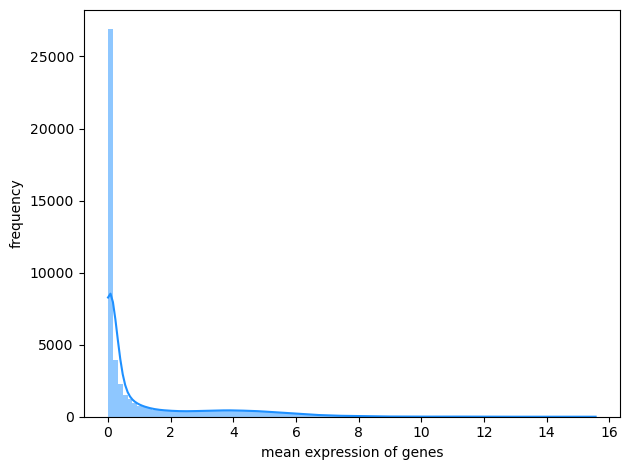

In [9]:
#Transcriptomics mean expression plot
plot_freq(transcriptomics.mean(),
          title='mean expression of genes', bins=100)

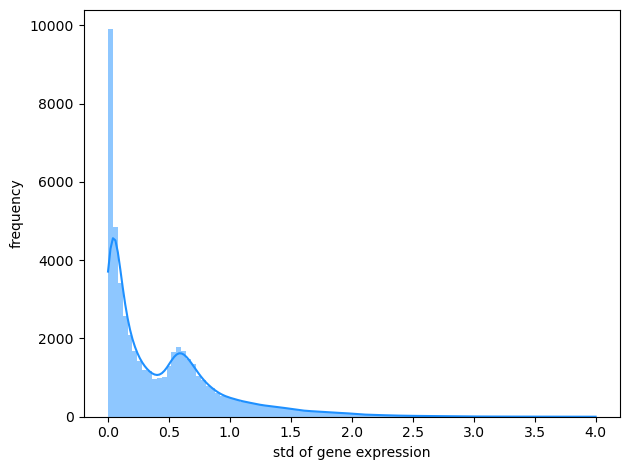

In [10]:
plot_freq(transcriptomics.std(),
          title='std of gene expression', bins=100)

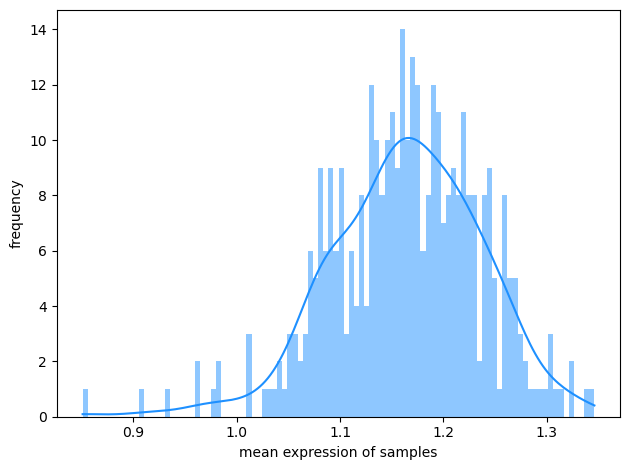

In [11]:
#Plot depicting distribution of mean expressions of samples
plot_freq(transcriptomics.T.mean(),
          title='mean expression of samples', bins=100)

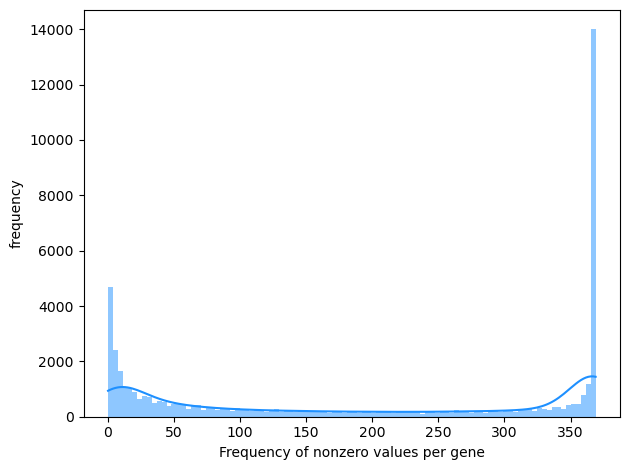

In [12]:
#Distribution of nonzero values per gene
plot_freq((transcriptomics != 0).sum(),
          title='Frequency of nonzero values per gene', bins=100)

## Mean Variance relationship

- Reducing the opacity of dots we can see that most genes belong to one of two dense areas
- The dense area on the left is unexpressed, the one on the right is expressed
- The left peak cannot be removed by filtering out low variable genes, as the right peak would also disappear

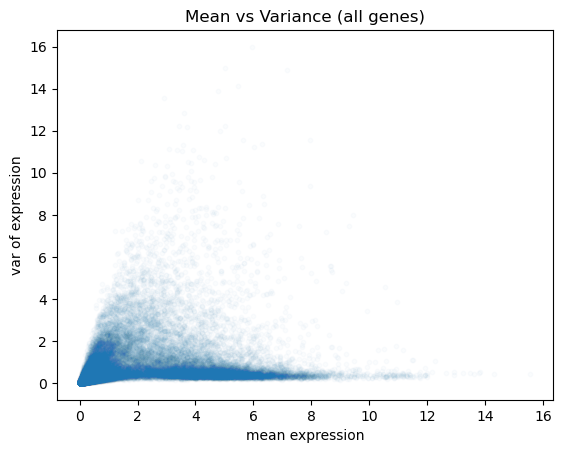

In [ ]:
# Mean variance plot (all genes without filtering)

# complete mean, variance
x_all = transcriptomics.mean()
y_all = transcriptomics.var()
plt.scatter(x_all, y_all, s=10, alpha=0.02)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')
plt.title('Mean vs Variance (all genes)')
# Show the plot
plt.show()



## Gene Filtering Strategy

We investigated different gene filtering strategies:
- variance filtering
- mena filtering
- zero filtering
- KDE local minimum filtering


### Variance expression filtering

Variance/STD threshold (horizontal cut) captures dispersion (informative variability across samples).
But misses high-mean but stable genes (biologically meaningful yet low variance) and no notion of how variance scales with mean.

In [ ]:
# Variance threshold
transcriptomics_var_filtered = transcriptomics.T[transcriptomics.var(ddof=1) > 0.5].T
# gene surviving after the variance filtering
transcriptomics_var_filtered.shape


(369, 11862)

In [ ]:
# Mean var plot
x = transcriptomics_var_filtered.mean()
y = transcriptomics_var_filtered.var()
z = (transcriptomics_var_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

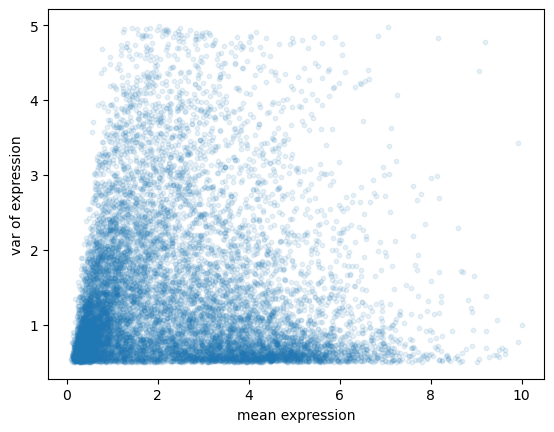

In [22]:
#Zoommed plot
x = transcriptomics_var_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_var_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_var_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.1)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

### Mean expression filtering

Mean threshold (vertical cut), captures overall abundance.
Misses to filter outgenes with moderate mean but obviously unexpressed in most samples and any correlation between mean and variability.

In [29]:
# Genes with low mean expression filtered out
transcriptomics_mean_filtered = transcriptomics.T[transcriptomics.mean() > 2].T
transcriptomics_mean_filtered.shape

(369, 11400)

In [30]:
# Proportion of genes filtered out
print(f"Filtered out {11400/51989:.2%} of low mean transcriptomics")
transcriptomics_mean_filtered.shape

Filtered out 21.93% of low mean transcriptomics


(369, 11400)

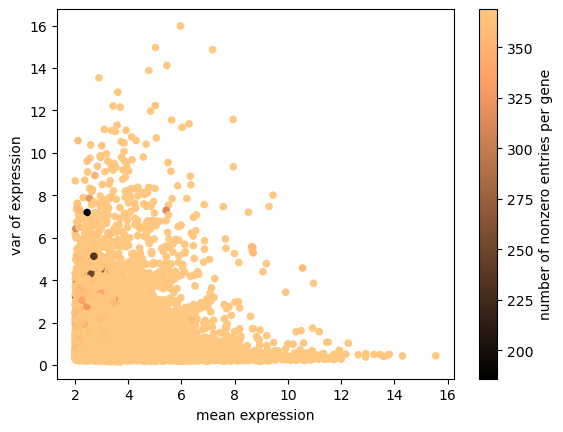

In [31]:
# Mean var plot
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

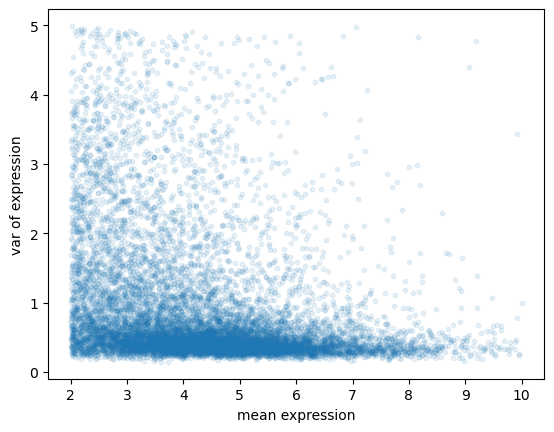

In [33]:
# Zoomed plot

x = transcriptomics_mean_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_mean_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.1)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

### Non-zeros count filtering

Non-zero count threshold captures prevalence across samples (consistency of expression). But it misses magnitude (a gene can be barely >0 but pass), and interplay with variance.

In [35]:
transcriptomics_nonzero_filtered = transcriptomics.T[(transcriptomics != 0).sum() > 300].T
transcriptomics_nonzero_filtered.shape
print(f"Filtered out {20653/51989:.2%} of zero entries transcriptomics")

Filtered out 39.73% of zero entries transcriptomics


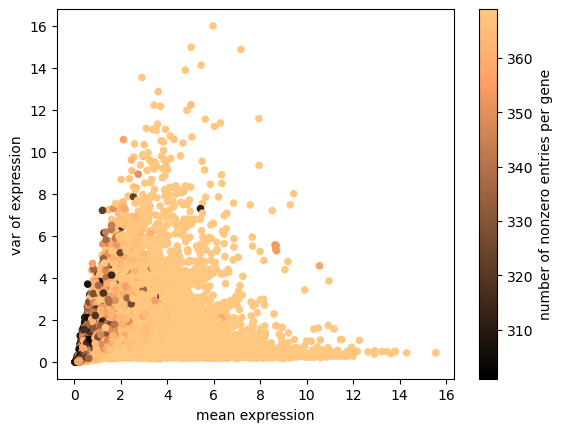

In [36]:
# MV of non zero filtered

x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

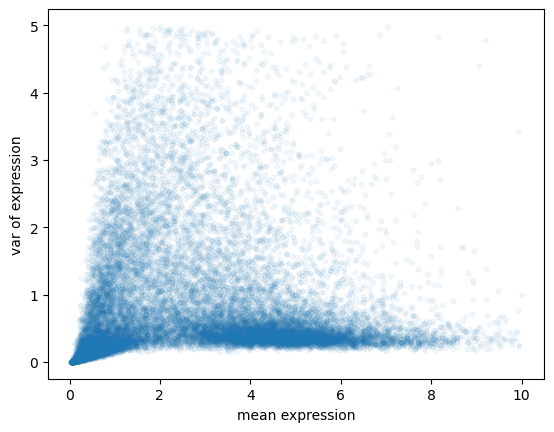

In [37]:
# Zoomed plot

x = transcriptomics_nonzero_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_nonzero_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_nonzero_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

## KDE Local Minimum Filtering

KDE local-minimum threshold finds the valley between low- and high-expression means, giving a data-adaptive magnitude cutoff.
It’s nonparametric, avoiding distributional assumptions, but implicitly assumes (at least) weak bimodality.
Outliers and scale can skew the cut; it’s better on normalized/log-transformed means (we apply it on log TPM data).
It captures intensity, not prevalence or dispersion pairing with a prevalence/variance filter improves robustness.

In [40]:
# KDE to find threshold for mean expression
data = transcriptomics.mean()

kde = gaussian_kde(data)

x_eval = np.linspace(data.min(), data.max(), 1000)
kde_vals = kde(x_eval)

mean_threshold = None

for i in range(1, len(kde_vals) - 1):
    if kde_vals[i - 1] > kde_vals[i] < kde_vals[i + 1]:
        local_min_x = x_eval[i]
        local_min_y = kde_vals[i]
        print(f"Local minimum at x = {local_min_x:.4f}, KDE = {local_min_y:.4f}")
        if mean_threshold == None:
            mean_threshold = local_min_x

Local minimum at x = 2.4919, KDE = 0.0472
Local minimum at x = 9.9833, KDE = 0.0009
Local minimum at x = 12.5843, KDE = 0.0001
Local minimum at x = 13.2073, KDE = 0.0001
Local minimum at x = 14.9360, KDE = 0.0000


In [41]:
# KDE to find threshold for std expression
data = transcriptomics.std()

kde = gaussian_kde(data)

x_eval = np.linspace(data.min(), data.max(), 1000)
kde_vals = kde(x_eval)

std_threshold = None

for i in range(1, len(kde_vals) - 1):
    if kde_vals[i - 1] > kde_vals[i] < kde_vals[i + 1]:
        local_min_x = x_eval[i]
        local_min_y = kde_vals[i]
        print(f"Local minimum at x = {local_min_x:.4f}, KDE = {local_min_y:.4f}")
        if std_threshold == None:
            std_threshold = local_min_x
        print(mean_threshold, std_threshold)

Local minimum at x = 0.4043, KDE = 0.5131
2.4919372332230365 0.40425836678523625
Local minimum at x = 2.9859, KDE = 0.0026
2.4919372332230365 0.40425836678523625
Local minimum at x = 3.6223, KDE = 0.0003
2.4919372332230365 0.40425836678523625
Local minimum at x = 3.8184, KDE = 0.0003
2.4919372332230365 0.40425836678523625


In [42]:
mean_threshold, std_threshold

(2.4919372332230365, 0.40425836678523625)

In [ ]:
# KDE filtering
transcriptomics_kde_filtered = transcriptomics.T[(transcriptomics.mean() >= mean_threshold) |
                                                 (transcriptomics.std() >= std_threshold)].T
transcriptomics.shape


(369, 51989)

In [ ]:
# Original transcriptomics dataset (no filtered)
transcriptomics.shape , transcriptomics_kde_filtered.shape
# KDE filtered transcriptomics dataset

(369, 22614)

 After applying the KDE-OR filter, the mean–variance scatter characteristically loses the dense left–bottom wedge (low mean, low variance) while preserving the high-mean ridge

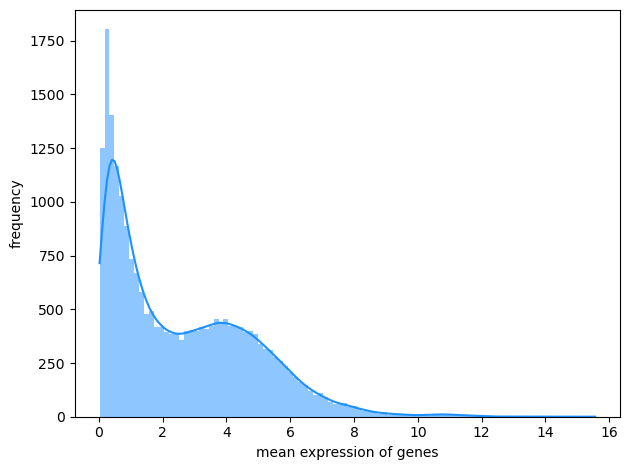

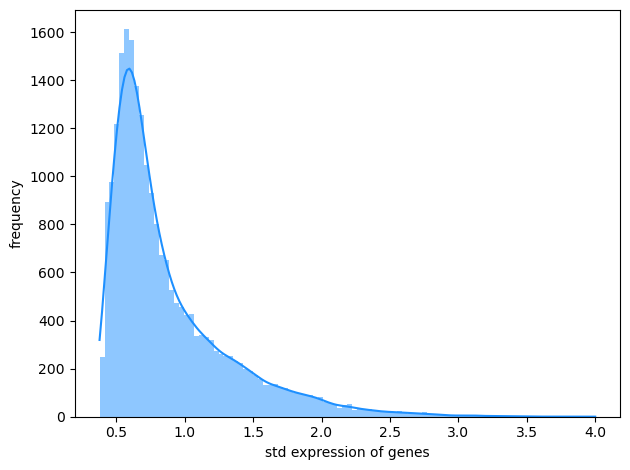

In [45]:
# Distributions of means and stds after KDE filtering
plot_freq(transcriptomics_kde_filtered.mean(),
          title='mean expression of genes', bins=100)

plot_freq(transcriptomics_kde_filtered.std(),
          title='std expression of genes', bins=100)

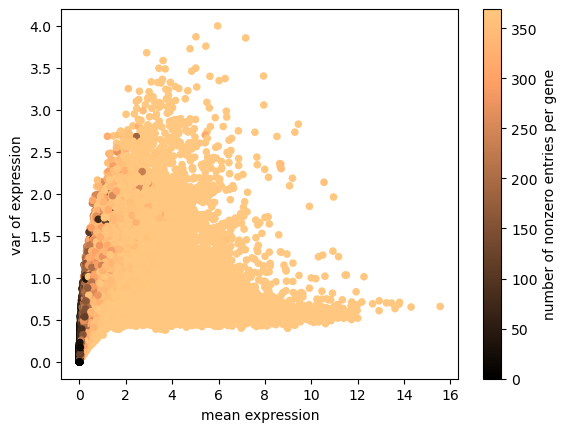

In [46]:
# MV before KDE filtering
x = transcriptomics.mean()
y = transcriptomics.std()
z = (transcriptomics != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

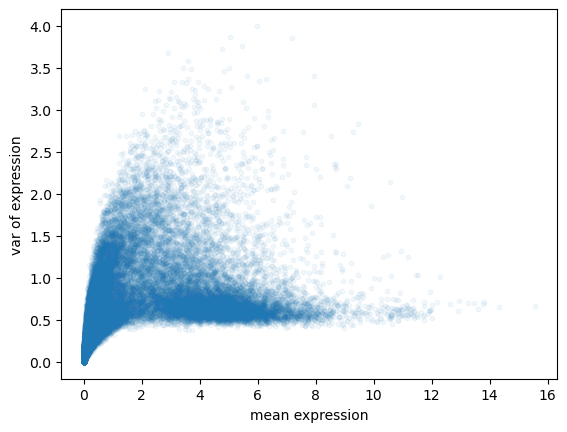

In [47]:
# MV before KDE filtering
x = transcriptomics.mean()
y = transcriptomics.std()

plt.scatter(x, y, cmap='copper', s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

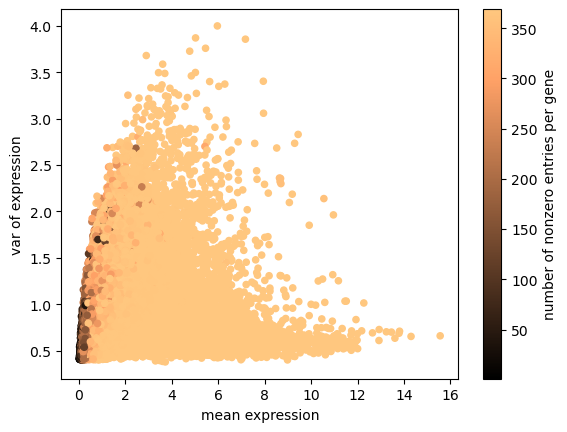

In [48]:
# MV after KDE filtering
x = transcriptomics_kde_filtered.mean()
y = transcriptomics_kde_filtered.std()
z = (transcriptomics_kde_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

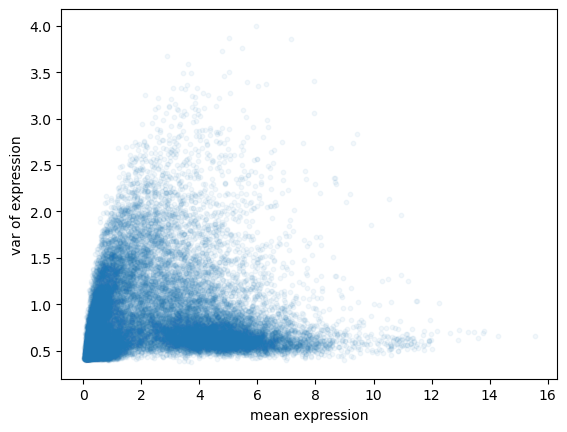

In [49]:
# MV before KDE filtering
x = transcriptomics_kde_filtered.mean()
y = transcriptomics_kde_filtered.std()

plt.scatter(x, y, cmap='copper', s=10, alpha=0.05)


# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

Std values form data distribution that mixes two regimes: low-quality samples with near-zero variability and higher-quality samples with substantial variability. A Gaussian KDE gives a smoothed estimate of that distribution; when it is bimodal, the valley between the modes is the most data-supported split. Using the first valley favors separating the near-zero cluster from the rest. Combining this with the KDE-derived mean threshold via an OR rule is deliberate: it keeps stable but well-expressed samples that a variance-only cut would wrongly discard, and it removes low-mean/low-std samples that a mean-only or non-zero rule often lets through. This is more adaptive and principled than fixed numbers (like “>2”) because the cut points come from the shape of your data rather than an arbitrary constant.

In [50]:
transcriptomics_kde_filtered

genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.263034,4.168321,5.244887,5.409391,0.189034,2.446256,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.150560,2.163499,6.280585,4.335569,0.014355,4.980939,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.070389,0.042644,5.667608,3.218781,0.056584,0.000000,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


A z-score is a standardized value computed as z=(x−μ)/σ, showing how many standard deviations x lies from the mean μ of its feature.
It centers data to mean 0 and scales to unit variance, enabling fair comparison across features with different units/scales.

CCLE/DepMap RNA-seq is released as log2(TPM+1) from a STAR→RSEM pipeline. TPM makes samples comparable by correcting for both gene length and sequencing depth: you first compute RPK (reads per kilobase) for each gene, then divide by the sample’s total RPK and multiply by 10⁶ to get “per million.”. In the following cell we do not compute TPM since we are assuming X already contains TPM values and then applying log2(TPM+1) to stabilize variance and shrink heavy tails. To this extent, we take the numeric features from df, apply the element-wise transform log2(x+1) (that is log2(TPM+1)) to produce a logged matrix, then computes per-feature z-scores on that logged matrix and stores both

For Elastic Net it is best Use log1p + per-feature standardization. Elastic Net’s L1/L2 penalties aren’t scale-invariant, so z-scoring equalizes shrinkage, and log1p makes features closer to Gaussian, improving fit and interpretation.

Instead for XGBoost it is best to use raw features or optionally log1p; don’t standardize. Trees split by order, which monotonic transforms preserve, so z-scores add no benefit and can introduce edge cases; a mild log1p can tame outliers.


On the other hand, standardization must be cross-fitted (causes leakage if done on the full data): any transform that uses across-sample stats (mean/std, PCA, quantile/Rank/QuantileTransformer, DESeq2/TMM size factors*). Doing these on the full dataset before CV biases results upward.

In [51]:
dump(transcriptomics_kde_filtered, 'data/transcriptomics_filtered.joblib')

['data/transcriptomics_filtered.joblib']